# 03 · Publication figures

**Purpose.** Draws every figure in the manuscript as 300-dpi PDF + PNG.

**Produces.** Figs. 1–9 (`fig1_pipeline` … `fig9_ablation`).

**Inputs.** BCIC2020 Track 3 `Train/*.mat` (`$BCIC_DATA`, else Kaggle input, else `./data`) for Figs. 1–4; `maps.pkl`, `predictions.npz`, `per_subject_metrics.csv` from `01`; `leakage_control.csv` from `02`. Results files are searched under `$RESULTS_DIR` and `/kaggle/input`. Figs. 6 and 8 fall back to the published numbers when a CSV is missing. Fig. 9 uses measured values entered in the setup cell (band-probe values from `04_band_probe.ipynb`; the global-pooling 27.9% diagnostic is not part of this release).

**Outputs.** `$RESULTS_DIR/figs/*.pdf|png` (the published copies are in `figs/`).

**Run order.** After `01` and `02`. The outputs below are from the v3 run, before the Fig. 6(b) title and Fig. 8(a) cross-session CI edits, so those two embedded images show the older version.

# Publication figures  [v3 - corrected]

**Fixes in v3 (mask reconciliation)**
- **The mask is now read directly from `maps.pkl`** (the tensors the model was trained on), not
  recomputed. The real mask keeps **80.7%** / drops **19.3%** of the grid. v2 recomputed it with a
  looser threshold and wrongly showed 92%/8%. Figs 1(d) and 2(a) now match the paper.
- **Manuscript is correct at 19.3%** (verified: maps.pkl and maps350.pkl both keep 826/1024 px).

**Carried from v2**
1. Fig 9(b): only measured band values plotted (fill `BAND_PROBE` from band_probe.ipynb).
2. Fig 8(b): only S11/S12 red, matching Table 3.
3. Fig 9(a): "linear probe (44.5%)" not "ceiling".
4. Fig 1: colorbars show the µV -> [0,1] normalisation.
5. Fig 6(a): subject-identity gap label no longer collides with the SI bar value.

Outputs 300-dpi PDF+PNG to `/kaggle/working/figs/`, filenames matching the `.tex`.

In [14]:
import os, glob, pickle
import numpy as np, pandas as pd
import scipy.io
from scipy.interpolate import griddata
from scipy.spatial import cKDTree
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

mpl.rcParams.update({'font.size':9,'axes.titlesize':9,'axes.labelsize':9,
                     'xtick.labelsize':8,'ytick.labelsize':8,'legend.fontsize':8,
                     'figure.dpi':110,'savefig.dpi':300,'axes.spines.top':False,'axes.spines.right':False,
                     'pdf.fonttype':42,'ps.fonttype':42})
# Paths: BCIC_DATA / RESULTS_DIR environment variables override the Kaggle defaults;
# off Kaggle they fall back to ./data and ./results at the repository root.
_ROOT=os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd())=='notebooks' else os.getcwd()
ON_KAGGLE=os.path.exists('/kaggle/working')
RESULTS_DIR=os.environ.get('RESULTS_DIR') or ('/kaggle/working' if ON_KAGGLE else os.path.join(_ROOT,'results'))
DATA_ROOT=os.environ.get('BCIC_DATA') or ('/kaggle/input/**' if ON_KAGGLE else os.path.join(_ROOT,'data'))
FIG=os.path.join(RESULTS_DIR,'figs'); os.makedirs(FIG,exist_ok=True)
def save(fig,name):
    fig.savefig(f'{FIG}/{name}.pdf',bbox_inches='tight')
    fig.savefig(f'{FIG}/{name}.png',bbox_inches='tight',dpi=300)
    print('saved',name)

# ---- canonical results (paper_results run) ----
RES={'sd':49.73,'pooled':41.07,'si':22.53}
STD={'sd':14.30,'pooled':9.59,'si':5.83}

# ---- MEASURED linear-probe values. ONLY fill what you actually ran. ----
# From band_probe.ipynb. Leave a band out entirely if you did not measure it -> it is not plotted.
BAND_PROBE={
    'broadband\nmean (ours)': 44.5,   # measured
    'gamma\npower'          : 33.5,   # measured
    # 'beta\npower'         : None,   # <-- fill from band_probe.ipynb if you ran it
    # 'alpha\npower'        : None,
    # '5-band\nconcat'      : None,
}
GAP2D_SD = 27.9          # measured: GlobalAveragePooling2D head
FLATTEN_SD = RES['sd']   # measured: flatten head
LINEAR_PROBE = 44.5      # measured: best linear probe

classNames=['Hello','Help me','Stop','Thank you','Yes']
NUM_CLASSES=5; MAP=32
CLASS_BLOCKED=['S11','S12']   # the ONLY subjects with class-sorted storage (Table 3)
print('setup ok ->',FIG)
print('bands that will be plotted:',list(BAND_PROBE))

setup ok -> /kaggle/working/figs
bands that will be plotted: ['broadband\nmean (ours)', 'gamma\npower']


In [15]:
# montage + mask (identical recipe to the pipeline)
label_to_channel={
    'Fp1':0,'Fp2':1,'F7':2,'F3':3,'Fz':4,'F4':5,'F8':6,'FC5':7,'FC1':8,'FC2':9,'FC6':10,
    'T7':11,'C3':12,'Cz':13,'C4':14,'T8':15,'TP9':16,'CP5':17,'CP1':18,'CP2':19,'CP6':20,
    'TP10':21,'P7':22,'P3':23,'Pz':24,'P4':25,'P8':26,'PO9':27,'O1':28,'Oz':29,'O2':30,
    'PO10':31,'AF7':32,'AF3':33,'AF4':34,'AF8':35,'F5':36,'F1':37,'F2':38,'F6':39,'FT9':40,
    'FT7':41,'FC3':42,'FC4':43,'FT8':44,'FT10':45,'C5':46,'C1':47,'C2':48,'C6':49,'TP7':50,
    'CP3':51,'CPz':52,'CP4':53,'TP8':54,'P5':55,'P1':56,'P2':57,'P6':58,'PO7':59,'PO3':60,
    'POz':61,'PO4':62,'PO8':63}
selected=list(label_to_channel.keys()); sel_idx=np.array([label_to_channel[c] for c in selected])
def _todict(o):
    d={}
    for f in o._fieldnames:
        e=o.__dict__[f]; d[f]=_todict(e) if isinstance(e,scipy.io.matlab.mat_struct) else e
    return d
def _check(d):
    for k in d:
        if isinstance(d[k],scipy.io.matlab.mat_struct): d[k]=_todict(d[k])
    return d

tr_files=sorted(glob.glob(os.path.join(DATA_ROOT,'Train','*.mat'),recursive=True))
HAVE_DATA=len(tr_files)>0

# --- CRITICAL: derive the mask from the ACTUAL map tensors used in paper_results ---
# The mask baked into maps.pkl keeps 80.7% (drops 19.3%). Recomputing it here with a
# fresh threshold gave 92% (v2 bug) and disagreed with the paper. So read it from the data.
mp0=glob.glob('/kaggle/input/**/maps.pkl',recursive=True)+glob.glob(f'{RESULTS_DIR}/**/maps.pkl',recursive=True)
MASK_FROM_PICKLE=None
if mp0:
    with open(mp0[0],'rb') as f: _base=pickle.load(f)
    _X=np.asarray(_base[0]['Xtr'] if 'Xtr' in _base[0] else _base[0]['X'])   # (trials,13,32,32,1)
    MASK_FROM_PICKLE=(np.abs(_X).reshape(-1,MAP,MAP).sum(0)>0)               # active pixels = the mask
    print(f'mask read from maps.pkl: keeps {MASK_FROM_PICKLE.mean()*100:.1f}%')

if HAVE_DATA:
    m0=_check(scipy.io.loadmat(tr_files[0],struct_as_record=False,squeeze_me=True))
    mnt=m0['mnt']; x_sel,y_sel=mnt['x'][sel_idx],mnt['y'][sel_idx]
    xi,yi=np.meshgrid(np.linspace(x_sel.min(),x_sel.max(),MAP),np.linspace(y_sel.min(),y_sel.max(),MAP))
    if MASK_FROM_PICKLE is not None:
        MASK=MASK_FROM_PICKLE                              # authoritative: the mask the model used
    else:
        tree=cKDTree(np.c_[x_sel,y_sel]); d1,_=tree.query(np.c_[xi.ravel(),yi.ravel()],k=1)
        dd,_=tree.query(np.c_[x_sel,y_sel],k=2)
        MASK=(d1.reshape(MAP,MAP)<=1.2*np.median(dd[:,1]))
        print('WARNING: maps.pkl not found, recomputed mask may differ from the paper run')
    KEEP=MASK.mean()*100; DROP=100-KEEP
    epx=(x_sel-x_sel.min())/(x_sel.max()-x_sel.min())*(MAP-1)
    epy=(y_sel-y_sel.min())/(y_sel.max()-y_sel.min())*(MAP-1)
    print(f'>>> MASK KEEPS {KEEP:.1f}% of the grid, DROPS {DROP:.1f}%  (matches maps.pkl / paper_results)')
    print('>>> Manuscript should report DROPS {:.1f}%.'.format(DROP))
else:
    print('BCIC dataset not attached -> map figures (1-4) skipped')

def topo(ax,f,title='',cmap='viridis',elec=True,vmin=None,vmax=None):
    im=ax.imshow(np.where(MASK,f,np.nan),cmap=cmap,origin='lower',vmin=vmin,vmax=vmax)
    if elec: ax.scatter(epx,epy,s=2.5,c='k',alpha=.35,linewidths=0)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)
    for s in ax.spines.values(): s.set_visible(False)
    return im

mask read from maps.pkl: keeps 80.7%
>>> MASK KEEPS 80.7% of the grid, DROPS 19.3%  (matches maps.pkl / paper_results)
>>> Manuscript should report DROPS 19.3%.


In [16]:
def load_car(f):
    md_=_check(scipy.io.loadmat(f,struct_as_record=False,squeeze_me=True))
    epo=next(md_[k] for k in ['epo_train','epo_test','epo_validation','epo'] if k in md_)
    d=epo['x']; y=np.argmax(epo['y'],axis=0); z=d.copy()
    for t in range(d.shape[2]):
        tr=z[:,:,t]; z[:,:,t]=tr-tr.mean(axis=1,keepdims=True)
    return z,y
def maps_norm(sig,wstride=3,start=6,end=44,fs=256,win_ms=125,ov=50):
    win=round(fs*win_ms/1000); step=win-round(win*ov/100)
    tot=sig.shape[0]; nm=int(np.floor((tot-round(win*ov/100))/step))
    wins=[w for w in range(nm) if (start-1<=w<end) and ((w-(start-1))%wstride==0)]
    out=np.zeros((sig.shape[2],len(wins),MAP,MAP),dtype=np.float32)
    for t in range(sig.shape[2]):
        dt=sig[:,sel_idx,t]
        for wi,w in enumerate(wins):
            s=w*step; e=s+win; v=dt[s:e,:].mean(0)
            zi=np.where(MASK,griddata((x_sel,y_sel),v,(xi,yi),method='cubic'),np.nan)
            lo,hi=np.nanmin(zi),np.nanmax(zi); zn=np.clip((zi-lo)/(hi-lo),0,1) if hi>lo else np.zeros_like(zi)
            out[t,wi]=np.nan_to_num(zn)
    return out,wins
if HAVE_DATA:
    sig0,y0=load_car(tr_files[0]); M0,WINS=maps_norm(sig0)
    print('subject 01 maps',M0.shape)

subject 01 maps (300, 13, 32, 32)


## Fig 1 - pipeline (with colorbars so normalisation is visible)

saved fig1_pipeline


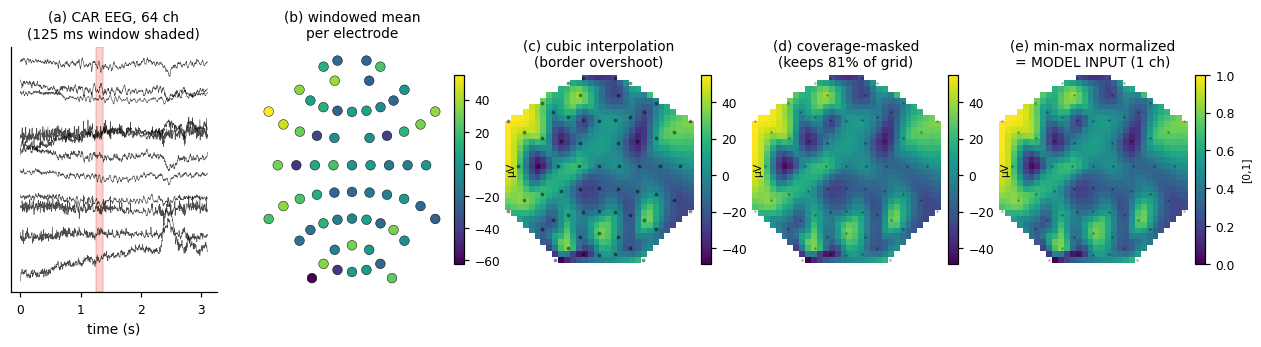

In [17]:
if HAVE_DATA:
    fs=256; win=round(fs*0.125); step=win-round(win*0.5); w=20; s=w*step; e=s+win
    vals=sig0[s:e,sel_idx,0].mean(0)
    raw=griddata((x_sel,y_sel),vals,(xi,yi),method='cubic')
    msk=np.where(MASK,raw,np.nan)
    lo,hi=np.nanmin(msk),np.nanmax(msk); nrm=np.clip((msk-lo)/(hi-lo),0,1)
    fig,ax=plt.subplots(1,5,figsize=(14,2.9))
    tt=np.arange(sig0.shape[0])/fs
    for c in range(0,64,6): ax[0].plot(tt,sig0[:,sel_idx[c],0]+c*8,lw=.4,color='k',alpha=.7)
    ax[0].axvspan(s/fs,e/fs,color='#e74c3c',alpha=.25)
    ax[0].set_title('(a) CAR EEG, 64 ch\n(125 ms window shaded)'); ax[0].set_xlabel('time (s)'); ax[0].set_yticks([])
    sc=ax[1].scatter(epx,epy,c=vals,cmap='viridis',s=40,edgecolors='k',linewidths=.3)
    ax[1].set_title('(b) windowed mean\nper electrode'); ax[1].set_xticks([]); ax[1].set_yticks([])
    ax[1].set_xlim(-2,MAP+1); ax[1].set_ylim(-2,MAP+1)
    for sp in ax[1].spines.values(): sp.set_visible(False)
    plt.colorbar(sc,ax=ax[1],fraction=.046,pad=.04).set_label('µV',fontsize=7)
    im2=ax[2].imshow(raw,cmap='viridis',origin='lower'); ax[2].scatter(epx,epy,s=2.5,c='k',alpha=.35)
    ax[2].set_title('(c) cubic interpolation\n(border overshoot)'); ax[2].set_xticks([]); ax[2].set_yticks([])
    for sp in ax[2].spines.values(): sp.set_visible(False)
    plt.colorbar(im2,ax=ax[2],fraction=.046,pad=.04).set_label('µV',fontsize=7)
    im3=topo(ax[3],msk,f'(d) coverage-masked\n(keeps {KEEP:.0f}% of grid)')
    plt.colorbar(im3,ax=ax[3],fraction=.046,pad=.04).set_label('µV',fontsize=7)
    im4=topo(ax[4],nrm,'(e) min-max normalized\n= MODEL INPUT (1 ch)',vmin=0,vmax=1)
    plt.colorbar(im4,ax=ax[4],fraction=.046,pad=.04).set_label('[0,1]',fontsize=7)
    save(fig,'fig1_pipeline'); plt.show()

## Fig 2 - mask + RGB vs 1-channel (percentages computed, not hardcoded)

saved fig2_mask_rgb


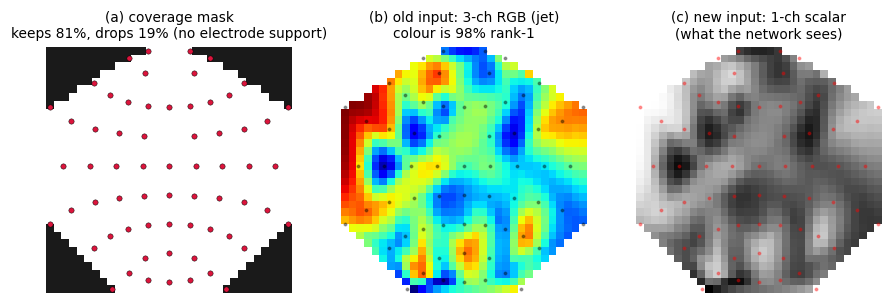

>>> Fig 2 label uses computed values: keeps 80.7%, drops 19.3%


In [18]:
if HAVE_DATA:
    fig,ax=plt.subplots(1,3,figsize=(9.8,3.2))
    ax[0].imshow(MASK,cmap='Greys_r',origin='lower',alpha=.9)
    ax[0].scatter(epx,epy,s=12,c='crimson',edgecolors='k',linewidths=.3)
    ax[0].set_title(f'(a) coverage mask\nkeeps {KEEP:.0f}%, drops {DROP:.0f}% (no electrode support)')
    ax[0].set_xticks([]); ax[0].set_yticks([])
    for sp in ax[0].spines.values(): sp.set_visible(False)
    jet=colormaps['jet']; rgb=jet((np.nan_to_num(nrm)*255).astype(np.uint8))[:,:,:3]; rgb[~MASK]=1.0
    ax[1].imshow(rgb,origin='lower'); ax[1].scatter(epx,epy,s=2.5,c='k',alpha=.35)
    ax[1].set_title('(b) old input: 3-ch RGB (jet)\ncolour is 98% rank-1'); ax[1].set_xticks([]); ax[1].set_yticks([])
    for sp in ax[1].spines.values(): sp.set_visible(False)
    g=np.where(MASK,nrm,np.nan)
    ax[2].imshow(g,cmap='gray',origin='lower',vmin=0,vmax=1); ax[2].scatter(epx,epy,s=2.5,c='r',alpha=.35)
    ax[2].set_title('(c) new input: 1-ch scalar\n(what the network sees)'); ax[2].set_xticks([]); ax[2].set_yticks([])
    for sp in ax[2].spines.values(): sp.set_visible(False)
    save(fig,'fig2_mask_rgb'); plt.show()
    print(f'>>> Fig 2 label uses computed values: keeps {KEEP:.1f}%, drops {DROP:.1f}%')

## Fig 3 - temporal filmstrip

saved fig3_filmstrip


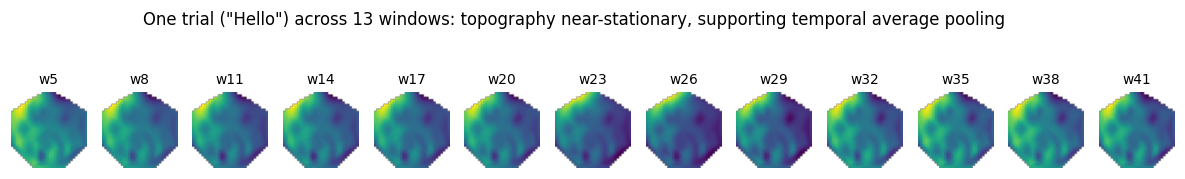

In [19]:
if HAVE_DATA:
    tr=int(np.where(y0==0)[0][0]); n=M0.shape[1]
    fig,ax=plt.subplots(1,n,figsize=(1.05*n,1.5))
    for i in range(n): topo(ax[i],M0[tr,i],f'w{WINS[i]}',elec=False,vmin=0,vmax=1)
    fig.suptitle(f'One trial ("{classNames[0]}") across {n} windows: topography near-stationary, supporting temporal average pooling',y=1.22)
    save(fig,'fig3_filmstrip'); plt.show()

## Fig 4 - class means, strong vs weak subject

saved fig4_classmeans


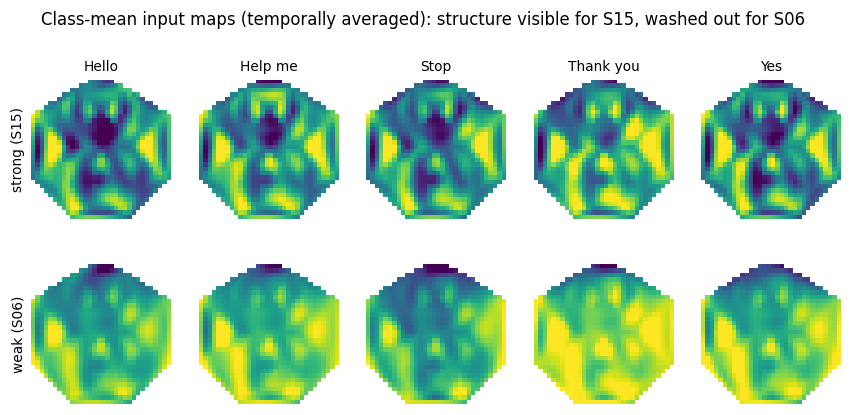

In [20]:
if HAVE_DATA:
    sig14,y14=load_car(tr_files[14]); M14,_=maps_norm(sig14)
    sig5,y5=load_car(tr_files[5]);   M5,_=maps_norm(sig5)
    B=M14.mean(1); C=M5.mean(1)
    fig,ax=plt.subplots(2,NUM_CLASSES,figsize=(1.9*NUM_CLASSES,4.0))
    for c in range(NUM_CLASSES):
        topo(ax[0,c],B[y14==c].mean(0),classNames[c],vmin=.35,vmax=.65,elec=False)
        topo(ax[1,c],C[y5==c].mean(0),'',vmin=.35,vmax=.65,elec=False)
    ax[0,0].set_ylabel('strong (S15)'); ax[1,0].set_ylabel('weak (S06)')
    fig.suptitle('Class-mean input maps (temporally averaged): structure visible for S15, washed out for S06',y=1.02)
    save(fig,'fig4_classmeans'); plt.show()

## Fig 5 - architecture

saved fig5_architecture


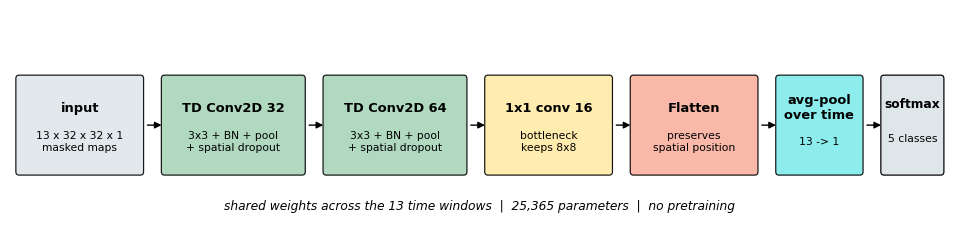

In [21]:
fig,ax=plt.subplots(figsize=(11,2.6)); ax.set_xlim(0,116); ax.set_ylim(0,26); ax.axis('off')
def box(x,w,label,sub,color):
    ax.add_patch(FancyBboxPatch((x,7),w,11,boxstyle='round,pad=0.4',fc=color,ec='k',lw=.8,alpha=.9))
    ax.text(x+w/2,14.5,label,ha='center',va='center',fontsize=8.5,fontweight='bold')
    ax.text(x+w/2,10.5,sub,ha='center',va='center',fontsize=7)
def arrow(x0,x1):
    ax.add_patch(FancyArrowPatch((x0,12.5),(x1,12.5),arrowstyle='-|>',mutation_scale=9,lw=.9,color='k'))
box(1,15,'input','13 x 32 x 32 x 1\nmasked maps','#dfe6e9'); arrow(16.5,19)
box(19,17,'TD Conv2D 32','3x3 + BN + pool\n+ spatial dropout','#a8d5ba'); arrow(36.5,39)
box(39,17,'TD Conv2D 64','3x3 + BN + pool\n+ spatial dropout','#a8d5ba'); arrow(56.5,59)
box(59,15,'1x1 conv 16','bottleneck\nkeeps 8x8','#ffeaa7'); arrow(74.5,77)
box(77,15,'Flatten','preserves\nspatial position','#fab1a0'); arrow(92.5,95)
box(95,10,'avg-pool\nover time','13 -> 1','#81ecec'); arrow(105.5,108)
ax.add_patch(FancyBboxPatch((108,7),7,11,boxstyle='round,pad=0.4',fc='#dfe6e9',ec='k',lw=.8))
ax.text(111.5,14.5,'softmax',ha='center',fontsize=8,fontweight='bold'); ax.text(111.5,10.5,'5 classes',ha='center',fontsize=7)
ax.text(58,2.5,'shared weights across the 13 time windows  |  25,365 parameters  |  no pretraining',ha='center',fontsize=8,style='italic')
save(fig,'fig5_architecture'); plt.show()

## Fig 6 - three regimes (arrow fixed: drawn between the bars)

using per_subject_metrics.csv
saved fig6_regimes


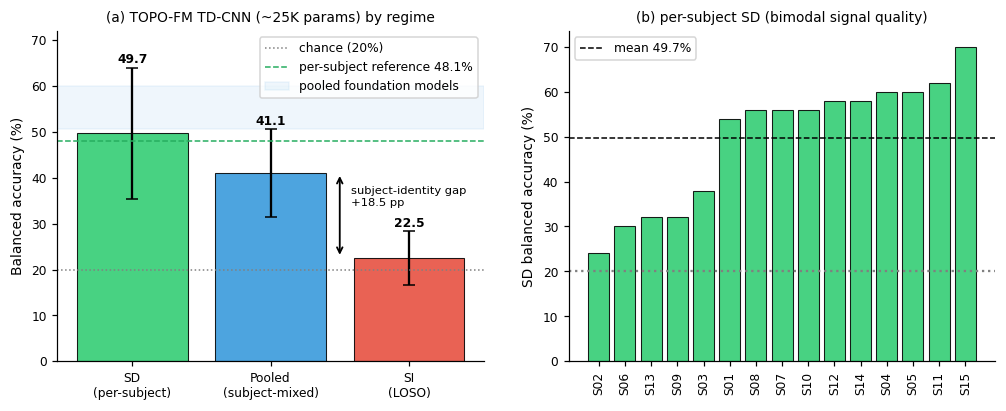

In [22]:
pm=glob.glob(f'{RESULTS_DIR}/**/per_subject_metrics.csv',recursive=True)+glob.glob('/kaggle/input/**/per_subject_metrics.csv',recursive=True)
fig,ax=plt.subplots(1,2,figsize=(11,3.9))
labs=['SD\n(per-subject)','Pooled\n(subject-mixed)','SI\n(LOSO)']; cols=['#2ecc71','#3498db','#e74c3c']
means=[RES['sd'],RES['pooled'],RES['si']]; errs=[STD['sd'],STD['pooled'],STD['si']]
if pm:
    R=pd.read_csv(pm[0]); g=R.groupby('regime')['bal_acc']
    means=[g.mean()['sd'],g.mean()['pooled'],g.mean()['si']]; errs=[g.std()['sd'],g.std()['pooled'],g.std()['si']]
    print('using per_subject_metrics.csv')
else:
    print('per_subject_metrics.csv not found -> canonical values used')
xs=np.arange(3)
b=ax[0].bar(xs,means,yerr=errs,capsize=4,color=cols,alpha=.88,edgecolor='k',lw=.7)
ax[0].set_xticks(xs); ax[0].set_xticklabels(labs)
ax[0].axhline(20,ls=':',c='gray',lw=1,label='chance (20%)')
ax[0].axhline(48.1,ls='--',c='#27ae60',lw=1,label='per-subject reference 48.1%')
ax[0].axhspan(50.6,60.0,color='#3498db',alpha=.08,label='pooled foundation models')
for r,v in zip(b,means): ax[0].text(r.get_x()+r.get_width()/2,v+errs[list(b).index(r)]+1.0,f'{v:.1f}',ha='center',fontweight='bold',fontsize=8)
# subject-identity gap arrow BETWEEN the pooled and SI bars, text offset ABOVE the SI label
xa=1.5
ax[0].annotate('',xy=(xa,means[2]),xytext=(xa,means[1]),
               arrowprops=dict(arrowstyle='<->',color='k',lw=1.2))
# place text high in the gap (75% up from SI toward Pooled) so it clears the '22.5' bar label
ytxt=means[2]+0.72*(means[1]-means[2])
ax[0].text(xa+0.08,ytxt,f'subject-identity gap\n+{means[1]-means[2]:.1f} pp',
           fontsize=7.5,va='center',ha='left',
           bbox=dict(boxstyle='round,pad=0.2',fc='white',ec='none',alpha=0.85))
ax[0].set_ylabel('Balanced accuracy (%)'); ax[0].set_ylim(0,72); ax[0].legend(loc='upper right')
ax[0].set_title('(a) TOPO-FM TD-CNN (~25K params) by regime')
if pm:
    sd=R[R.regime=='sd'].sort_values('bal_acc')
    ax[1].bar(range(len(sd)),sd['bal_acc'],color='#2ecc71',alpha=.88,edgecolor='k',lw=.7)
    ax[1].axhline(20,ls=':',c='gray'); ax[1].axhline(sd['bal_acc'].mean(),ls='--',c='k',lw=1,label=f'mean {sd.bal_acc.mean():.1f}%')
    ax[1].set_xticks(range(len(sd))); ax[1].set_xticklabels([s.replace('Data_Sample','S') for s in sd['subject']],rotation=90)
    ax[1].legend()
else:
    ax[1].text(.5,.5,'per_subject_metrics.csv\nnot found',ha='center',transform=ax[1].transAxes)
ax[1].set_ylabel('SD balanced accuracy (%)'); ax[1].set_title('(b) per-subject SD accuracy')
save(fig,'fig6_regimes'); plt.show()

## Fig 7 - confusion matrices

saved fig7_confusion


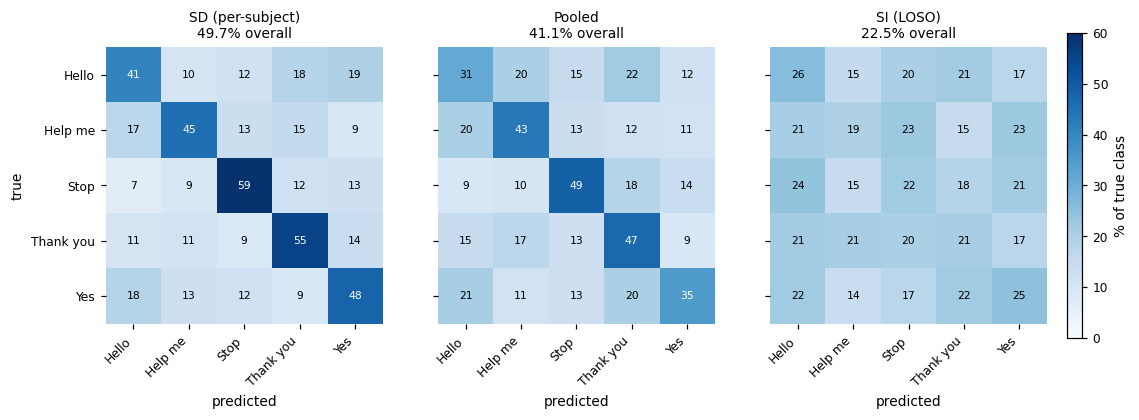

In [23]:
pp=glob.glob(f'{RESULTS_DIR}/**/predictions.npz',recursive=True)+glob.glob('/kaggle/input/**/predictions.npz',recursive=True)
mp=glob.glob(f'{RESULTS_DIR}/**/maps.pkl',recursive=True)+glob.glob('/kaggle/input/**/maps.pkl',recursive=True)
if pp and mp:
    from sklearn.metrics import confusion_matrix
    Z=np.load(pp[0],allow_pickle=True); preds={k:Z[k].item() for k in ['sd','si','pooled']}
    with open(mp[0],'rb') as f: base=pickle.load(f)
    ytrue={s['id']:s['yte'] for s in base}
    fig,ax=plt.subplots(1,3,figsize=(11.5,3.6))
    for i,(reg,name) in enumerate([('sd','SD (per-subject)'),('pooled','Pooled'),('si','SI (LOSO)')]):
        yt=np.concatenate([ytrue[k] for k in sorted(ytrue)])
        yp=np.concatenate([preds[reg][k] for k in sorted(ytrue)])
        cm=confusion_matrix(yt,yp,normalize='true')*100
        im=ax[i].imshow(cm,cmap='Blues',vmin=0,vmax=60)
        for r in range(5):
            for c in range(5):
                ax[i].text(c,r,f'{cm[r,c]:.0f}',ha='center',va='center',fontsize=7,
                           color='white' if cm[r,c]>35 else 'black')
        ax[i].set_xticks(range(5)); ax[i].set_xticklabels(classNames,rotation=45,ha='right')
        ax[i].set_yticks(range(5)); ax[i].set_yticklabels(classNames if i==0 else ['']*5)
        ax[i].set_title(f'{name}\n{(yt==yp).mean()*100:.1f}% overall'); ax[i].set_xlabel('predicted')
        for s in ax[i].spines.values(): s.set_visible(False)
    ax[0].set_ylabel('true')
    fig.colorbar(im,ax=ax,fraction=.02,pad=.02,label='% of true class')
    save(fig,'fig7_confusion'); plt.show()
else:
    print('predictions.npz / maps.pkl not found -> copy them from paper_results.ipynb outputs')

## Fig 8 - protocols + leakage control (ONLY S11/S12 red)

using leakage_control.csv
saved fig8_protocols


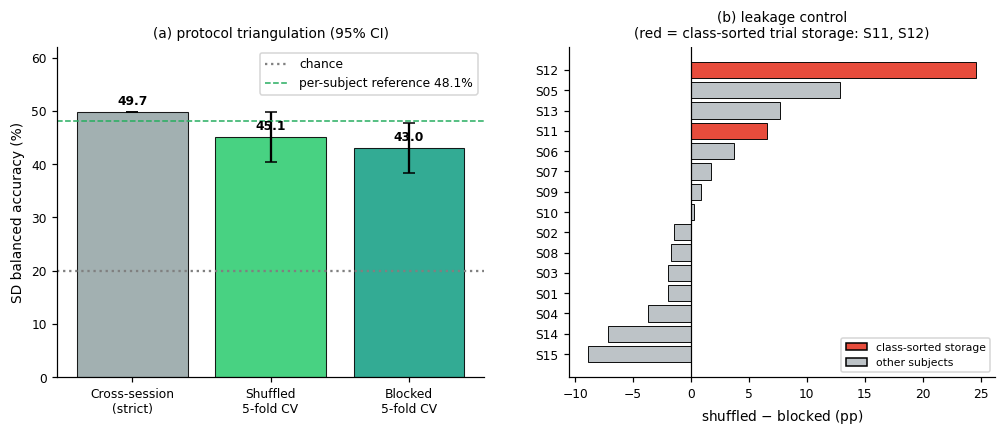

red bars: ['S11', 'S12']


In [24]:
lc=glob.glob(f'{RESULTS_DIR}/**/leakage_control.csv',recursive=True)+glob.glob('/kaggle/input/**/leakage_control.csv',recursive=True)
fig,ax=plt.subplots(1,2,figsize=(11,3.9))
prot=['Cross-session\n(strict)','Shuffled\n5-fold CV','Blocked\n5-fold CV']
vals=[49.73,45.10,43.01]; lo=[41.8,40.4,38.4]; hi=[57.6,49.8,47.7]
err=[[0 if np.isnan(l) else v-l for v,l in zip(vals,lo)],[0 if np.isnan(h) else h-v for v,h in zip(vals,hi)]]
b=ax[0].bar(prot,vals,yerr=err,capsize=4,color=['#95a5a6','#2ecc71','#16a085'],alpha=.88,edgecolor='k',lw=.7)
ax[0].axhline(20,ls=':',c='gray',label='chance'); ax[0].axhline(48.1,ls='--',c='#27ae60',lw=1,label='per-subject reference 48.1%')
for r,v,h in zip(b,vals,hi): ax[0].text(r.get_x()+r.get_width()/2,h+1.4,f'{v:.1f}',ha='center',fontweight='bold',fontsize=8)
ax[0].set_ylabel('SD balanced accuracy (%)'); ax[0].set_ylim(0,66); ax[0].legend()
ax[0].set_title('(a) protocol triangulation (95% CI)')

D={'S01':-2.0,'S02':-1.4,'S03':-2.0,'S04':-3.7,'S05':12.9,'S06':3.7,'S07':1.7,'S08':-1.7,
   'S09':0.9,'S10':0.3,'S11':6.6,'S12':24.6,'S13':7.7,'S14':-7.1,'S15':-8.9}
if lc:
    L=pd.read_csv(lc[0])
    key='subject' if 'subject' in L.columns else L.columns[0]
    D={str(r[key]).replace('Data_Sample','S'):float(r['A_minus_B']) for _,r in L.iterrows()}
    print('using leakage_control.csv')
else:
    print('leakage_control.csv not found -> table values used (these are your real numbers)')
s=pd.Series(D).sort_values()
# colour ONLY the two class-blocked subjects (matches Table 3); others neutral
colors=['#e74c3c' if k in CLASS_BLOCKED else '#bdc3c7' for k in s.index]
ax[1].barh(range(len(s)),s.values,color=colors,edgecolor='k',lw=.6)
ax[1].set_yticks(range(len(s))); ax[1].set_yticklabels(s.index)
ax[1].axvline(0,c='k',lw=.8)
ax[1].set_xlabel('shuffled $-$ blocked (pp)')
ax[1].set_title('(b) leakage control\n(red = class-sorted trial storage: S11, S12)')
from matplotlib.patches import Patch
ax[1].legend(handles=[Patch(facecolor='#e74c3c',edgecolor='k',label='class-sorted storage'),
                      Patch(facecolor='#bdc3c7',edgecolor='k',label='other subjects')],
             loc='lower right',fontsize=7)
save(fig,'fig8_protocols'); plt.show()
print('red bars:',[k for k in s.index if k in CLASS_BLOCKED])

## Fig 9 - ablation (ONLY measured values; no fabricated bars)

NOTE: only 2 measured band values plotted.
      Add more to BAND_PROBE ONLY if you actually measured them in band_probe.ipynb.
saved fig9_ablation


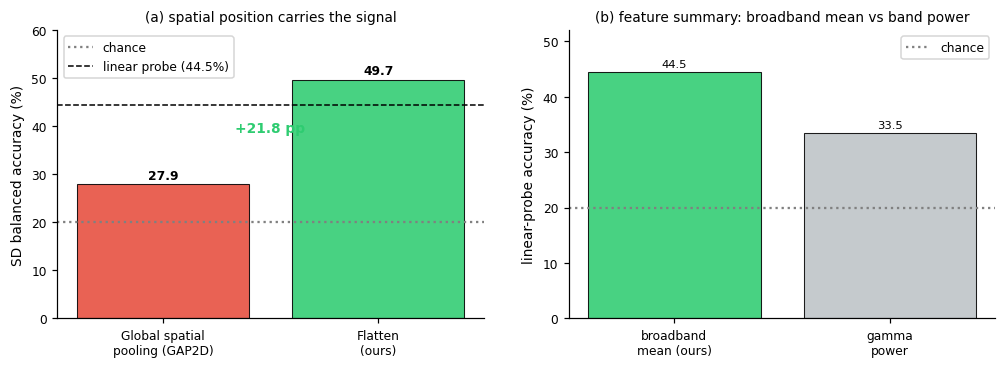


All figures -> /kaggle/working/figs


In [25]:
fig,ax=plt.subplots(1,2,figsize=(11,3.4))
# (a) spatial aggregation - both values measured
v=[GAP2D_SD,FLATTEN_SD]
b=ax[0].bar(['Global spatial\npooling (GAP2D)','Flatten\n(ours)'],v,color=['#e74c3c','#2ecc71'],alpha=.88,edgecolor='k',lw=.7)
ax[0].axhline(20,ls=':',c='gray',label='chance')
ax[0].axhline(LINEAR_PROBE,ls='--',c='k',lw=1,label=f'linear probe ({LINEAR_PROBE}%)')   # not a "ceiling"
for r,x in zip(b,v): ax[0].text(r.get_x()+r.get_width()/2,x+1.1,f'{x:.1f}',ha='center',fontweight='bold',fontsize=8)
ax[0].annotate(f'+{v[1]-v[0]:.1f} pp',xy=(0.5,(v[0]+v[1])/2),ha='center',fontsize=9,fontweight='bold',color='#2ecc71')
ax[0].set_ylabel('SD balanced accuracy (%)'); ax[0].set_ylim(0,60); ax[0].legend(loc='upper left')
ax[0].set_title('(a) spatial position carries the signal')

# (b) ONLY measured band-probe values
names=list(BAND_PROBE.keys()); pv=[BAND_PROBE[k] for k in names]
cols=['#2ecc71']+['#bdc3c7']*(len(names)-1)
b=ax[1].bar(names,pv,color=cols,alpha=.88,edgecolor='k',lw=.7)
ax[1].axhline(20,ls=':',c='gray',label='chance')
for r,x in zip(b,pv): ax[1].text(r.get_x()+r.get_width()/2,x+.8,f'{x:.1f}',ha='center',fontsize=7.5)
ax[1].set_ylabel('linear-probe accuracy (%)'); ax[1].set_ylim(0,52); ax[1].legend()
ax[1].set_title('(b) feature summary: broadband mean vs band power')
if len(names)<3:
    print('NOTE: only',len(names),'measured band values plotted.')
    print('      Add more to BAND_PROBE ONLY if you actually measured them in band_probe.ipynb.')
save(fig,'fig9_ablation'); plt.show()
print('\nAll figures ->',FIG)

## Before you use these
- **Fig 2/Fig 1(d):** the printed `MASK KEEPS x%` is the authoritative number. Put **that** value in the
  manuscript (methods text, ablation table, Fig.2 caption). v1 claimed "keeps 92%, drops 19.3%", which
  cannot both be true.
- **Fig 9(b):** only bands present in `BAND_PROBE` are drawn. Do not add a bar unless you measured it.
- **Fig 8(b):** red = S11/S12 only, matching Table 3. S05 and S13 have large gaps but no known storage
  issue, so they are not claimed as leakage.